# Prepare dataset

In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from PIL import Image
import planetary_computer
import rasterio
from rasterio.transform import from_origin
from rasterio.warp import transform, reproject
from pystac_client import Client
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from IPython.display import display, Markdown

SEED = 42
LAB_DIR = Path('lab_3') if Path('lab_3').exists() else Path('.')
IMAGE_DIR = LAB_DIR / 'images'
IMAGE_DIR.mkdir(exist_ok=True)
CLASSES = ['Forest', 'Urban']
BANDS = ['R', 'G', 'B']
COLORS = np.array([[0, 70, 255], [255, 30, 30]], dtype=np.uint8)

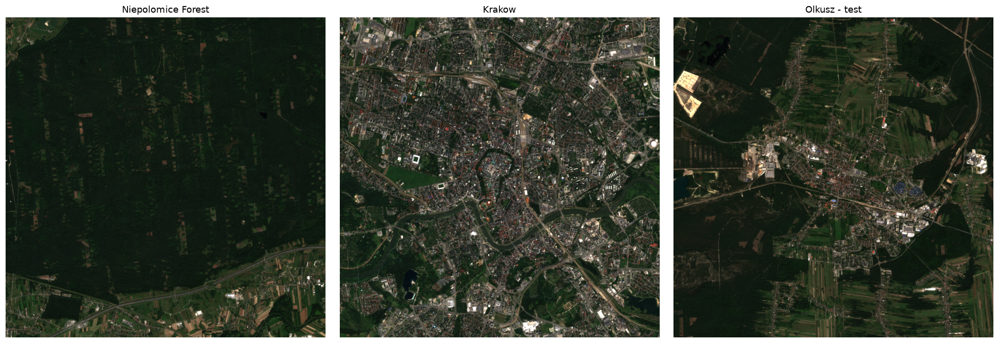

In [14]:
SIZE = 768
sites = {
    'forest': ('Niepolomice Forest', 20.37, 50.02),
    'urban': ('Krakow', 19.94, 50.06),
    'test': ('Olkusz - test', 19.56, 50.28),
}
images = {}
catalog = None
for name, (title, lon, lat) in sites.items():
    path = IMAGE_DIR / f'{name}_sentinel2.png'
    if not path.exists():
        if catalog is None:
            catalog = Client.open('https://planetarycomputer.microsoft.com/api/stac/v1',
                                  modifier=planetary_computer.sign_inplace)
        search = catalog.search(
            collections=['sentinel-2-l2a'],
            bbox=[lon - 0.01, lat - 0.01, lon + 0.01, lat + 0.01],
            datetime='2024-08-01/2024-08-31',
            query={'eo:cloud_cover': {'lt': 10}},
            sortby=[{'field': 'properties.eo:cloud_cover', 'direction': 'asc'}],
            max_items=1,
        )
        item = next(search.items())
        x, y = transform('EPSG:4326', 'EPSG:32634', [lon], [lat])
        grid = from_origin(round(x[0] / 10) * 10 - SIZE * 5,
                           round(y[0] / 10) * 10 + SIZE * 5, 10, 10)
        channels = []
        with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR'):
            for band in ['B04', 'B03', 'B02']:
                with rasterio.open(item.assets[band].href) as src:
                    out = np.zeros((SIZE, SIZE), dtype=np.uint16)
                    reproject(rasterio.band(src, 1), out,
                              src_transform=src.transform, src_crs=src.crs,
                              dst_transform=grid, dst_crs='EPSG:32634')
                channels.append(out)
        pixels = np.stack(channels, axis=-1).astype(float)
        pixels = np.clip((pixels - 1000) / 3000, 0, 1)
        Image.fromarray((pixels * 255).astype('uint8')).save(path)
    with Image.open(path) as image:
        images[name] = np.array(image.convert('RGB'))


def rgb(image):
    return image / 255.0


fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, (title, _, _)) in zip(axes, sites.items()):
    ax.imshow(images[name])
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

Sample 1,000 pixels per class from the training rectangles and use separate test rectangles to measure accuracy.

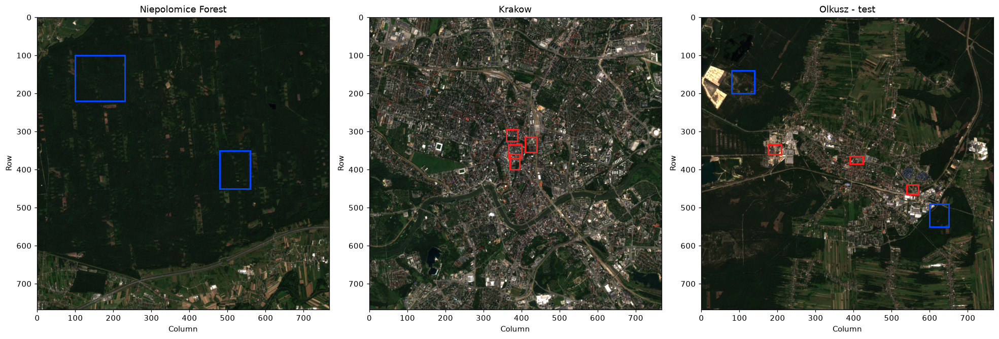

In [15]:
# Coordinates: row start, row stop, column start, column stop.
train_regions = {
    'forest': [(100, 220, 100, 230), (350, 450, 480, 560)],
    'urban': [(295, 325, 360, 390), (335, 370, 365, 400),
              (315, 355, 410, 440), (360, 400, 370, 395)],
}
test_regions = {
    0: [(140, 200, 80, 140), (490, 550, 600, 650)],
    1: [(365, 385, 390, 425), (335, 360, 175, 210), (440, 465, 540, 570)],
}


def crop(image, box):
    y0, y1, x0, x1 = box
    return image[y0:y1, x0:x1]


fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, name in zip(axes, sites):
    ax.imshow(rgb(images[name]))
    groups = test_regions if name == 'test' else {int(name == 'urban'): train_regions[name]}
    for label, boxes in groups.items():
        for y0, y1, x0, x1 in boxes:
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0,
                                   fill=False, edgecolor=COLORS[label] / 255, linewidth=2))
    ax.set_title(sites[name][0])
    ax.set_xlabel('Column')
    ax.set_ylabel('Row')
plt.tight_layout()
plt.show()

pools = [np.concatenate([crop(images[name], b).reshape(-1, 3)
                         for b in train_regions[name]]).astype(float)
         for name in ['forest', 'urban']]
rng = np.random.default_rng(SEED)
X_train = np.concatenate([pool[rng.choice(len(pool), 1000, replace=False)] for pool in pools])
y_train = np.repeat([0, 1], 1000)
X_test = images['test'].reshape(-1, 3).astype(float)
truth = np.full((SIZE, SIZE), -1, dtype=np.int8)
for label, boxes in test_regions.items():
    for y0, y1, x0, x1 in boxes:
        truth[y0:y1, x0:x1] = label
eval_mask = truth.ravel() >= 0
y_eval = truth.ravel()[eval_mask]

# Design a Bayes' classifier

Fit one Gaussian per class using its mean and covariance, and plot the RGB histograms with Gaussian PDFs.

,class,band,mean,std,prior
0,Forest,R,16.152,5.147,0.5
1,Forest,G,27.209,5.061,0.5
2,Forest,B,17.988,3.205,0.5
3,Urban,R,72.457,37.136,0.5
4,Urban,G,70.348,34.142,0.5
5,Urban,B,62.904,33.452,0.5


Forest covariance:


,R,G,B
R,26.49,21.51,14.44
G,21.51,25.62,13.66
B,14.44,13.66,10.27


Urban covariance:


,R,G,B
R,1379.11,1191.16,1144.67
G,1191.16,1165.64,1111.48
B,1144.67,1111.48,1119.01


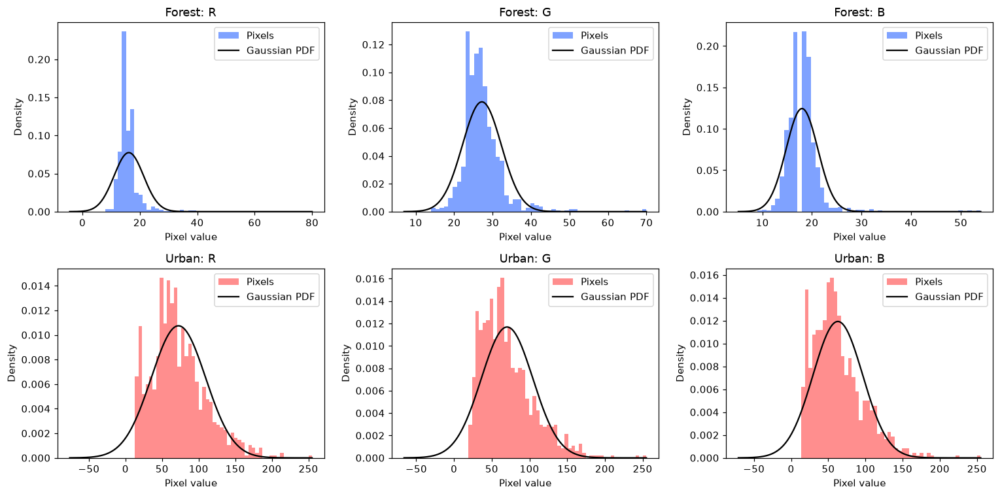

In [16]:
means = np.stack([X_train[y_train == c].mean(axis=0) for c in [0, 1]])
covariances = []
for c in [0, 1]:
    centered = X_train[y_train == c] - means[c]
    covariance = centered.T @ centered / len(centered)
    covariance += np.eye(3) * 0.001
    covariances.append(covariance)
covariances = np.stack(covariances)
priors = np.array([0.5, 0.5])
stds = np.sqrt(np.diagonal(covariances, axis1=1, axis2=2))
display(pd.DataFrame([
    {'class': CLASSES[c], 'band': band, 'mean': means[c, j],
     'std': stds[c, j], 'prior': priors[c]}
    for c in [0, 1] for j, band in enumerate(BANDS)
]).round(3))
for c in [0, 1]:
    print(CLASSES[c], 'covariance:')
    display(pd.DataFrame(covariances[c], index=BANDS, columns=BANDS).round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for c in [0, 1]:
    for j, band in enumerate(BANDS):
        ax = axes[c, j]
        values = X_train[y_train == c, j]
        grid = np.linspace(min(values.min(), means[c, j] - 4 * stds[c, j]),
                           max(values.max(), means[c, j] + 4 * stds[c, j]), 500)
        pdf = np.exp(-0.5 * ((grid - means[c, j]) / stds[c, j]) ** 2) / (stds[c, j] * np.sqrt(2 * np.pi))
        ax.hist(values, bins=50, density=True, alpha=0.5, color=COLORS[c] / 255, label='Pixels')
        ax.plot(grid, pdf, color='black', label='Gaussian PDF')
        ax.set(title=f'{CLASSES[c]}: {band}', xlabel='Pixel value', ylabel='Density')
        ax.legend()
plt.tight_layout()
plt.show()

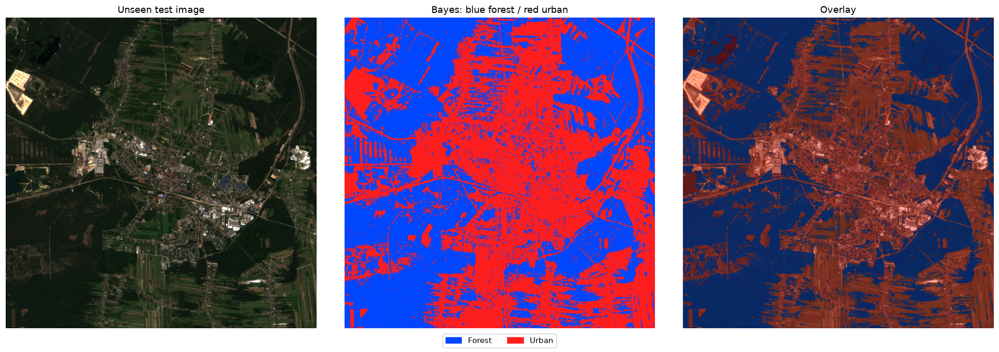

,model,accuracy,balanced accuracy
0,Bayes,0.6973,0.7857


In [17]:
def bayes_predict(X, means, covariances, priors):
    scores = []
    for mean, covariance, prior in zip(means, covariances, priors):
        difference = X - mean
        _, logdet = np.linalg.slogdet(covariance)
        mahalanobis = np.sum(difference * np.linalg.solve(covariance, difference.T).T, axis=1)
        scores.append(np.log(prior) - 0.5 * (logdet + mahalanobis))
    return np.argmax(np.column_stack(scores), axis=1).astype(np.uint8)


def report(name, prediction):
    selected = prediction[eval_mask]
    return {'model': name, 'accuracy': accuracy_score(y_eval, selected),
            'balanced accuracy': balanced_accuracy_score(y_eval, selected)}


def show_map(prediction, title):
    colored = COLORS[prediction.reshape(SIZE, SIZE)]
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(rgb(images['test']))
    axes[0].set_title('Unseen test image')
    axes[1].imshow(colored)
    axes[1].set_title(title)
    axes[2].imshow(0.65 * rgb(images['test']) + 0.35 * colored / 255)
    axes[2].set_title('Overlay')
    for ax in axes:
        ax.axis('off')
    fig.legend(handles=[Patch(color=COLORS[c] / 255, label=CLASSES[c]) for c in [0, 1]],
               loc='lower center', ncol=2)
    plt.tight_layout(rect=[0, 0.04, 1, 1])
    plt.show()


bayes_prediction = bayes_predict(X_test, means, covariances, priors)
rows = [report('Bayes', bayes_prediction)]
show_map(bayes_prediction, 'Bayes: blue forest / red urban')
display(pd.DataFrame(rows).round(4))

Overlapping colors and shadows can cause classification errors.

# Design a kNN classifier

In [18]:
scale_mean = X_train.mean(axis=0)
scale_std = X_train.std(axis=0)
scale_std = np.maximum(scale_std, 1.0)
train_z = (X_train - scale_mean) / scale_std
test_z = (X_test - scale_mean) / scale_std


def knn_predict_all(X, training, labels, ks=(1, 3, 5), batch_size=1024):
    predictions = {k: np.empty(len(X), dtype=np.uint8) for k in ks}
    max_k = max(ks)
    for start in range(0, len(X), batch_size):
        batch = X[start:start + batch_size]
        distances = np.zeros((len(batch), len(training)), dtype=float)
        for feature in range(training.shape[1]):
            distances += (batch[:, None, feature] - training[None, :, feature]) ** 2
        nearest = np.argsort(distances, axis=1, kind='stable')[:, :max_k]
        neighbor_labels = labels[nearest]
        for k in ks:
            predictions[k][start:start + len(batch)] = (neighbor_labels[:, :k].sum(axis=1) > k / 2)
    return predictions

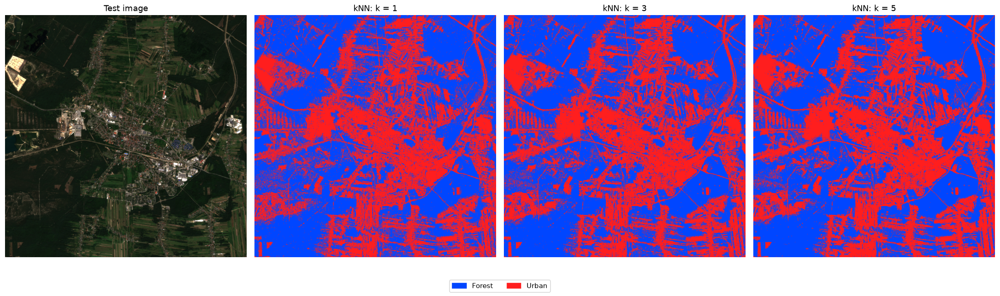

,accuracy,balanced accuracy
model,,
Bayes,0.6973,0.7857
kNN k=1,0.6781,0.7532
kNN k=3,0.6577,0.7447
kNN k=5,0.6653,0.7560


In [19]:
knn_predictions = knn_predict_all(test_z, train_z, y_train)
for k, prediction in knn_predictions.items():
    rows.append(report(f'kNN k={k}', prediction))

fig, axes = plt.subplots(1, 4, figsize=(20, 6))
axes[0].imshow(rgb(images['test']))
axes[0].set_title('Test image')
for ax, (k, prediction) in zip(axes[1:], knn_predictions.items()):
    ax.imshow(COLORS[prediction.reshape(SIZE, SIZE)])
    ax.set_title(f'kNN: k = {k}')
for ax in axes:
    ax.axis('off')
fig.legend(handles=[Patch(color=COLORS[c] / 255, label=CLASSES[c]) for c in [0, 1]],
           loc='lower center', ncol=2)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

results = pd.DataFrame(rows).set_index('model')
display(results.round(4))

In [20]:
for k in [1, 3, 5]:
    score = results.loc[f'kNN k={k}', 'balanced accuracy']
    display(Markdown(f'For k = {k}, balanced accuracy is {score:.1%} on the labelled test areas.'))

changed = np.mean(knn_predictions[1] != knn_predictions[5])
display(Markdown(
    f'Changing k from 1 to 5 changes {changed:.1%} of pixel labels; larger k makes voting less sensitive to individual samples.'))

For k = 1, balanced accuracy is 75.3% on the labelled test areas.

For k = 3, balanced accuracy is 74.5% on the labelled test areas.

For k = 5, balanced accuracy is 75.6% on the labelled test areas.

Changing k from 1 to 5 changes 12.9% of pixel labels; larger k makes voting less sensitive to individual samples.